# Dynamic Pricing for Ride-Sharing — Reinforcement Learning & Genetic Algorithm
### H9AIDM (AI-Driven Decision Making) — CA2 &nbsp;·&nbsp; MSc Artificial Intelligence, NCI
 Prasanth oddepally , x25205595s@studnet.ncirl.ie

## imports

In [2]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
np.set_printoptions(suppress=True)
DATA_PATH = r"C:\Users\msi\OneDrive\Desktop\H9AIDM\Data\rideshare_kaggle.csv"
OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)
SURGE_LEVELS = [1.0, 1.25, 1.5, 1.75, 2.0, 2.5, 3.0]
RANDOM_SEED = 0
print("Environment ready. Outputs ->", os.path.abspath(OUTPUT_DIR))

Environment ready. Outputs -> c:\Users\msi\OneDrive\Desktop\H9AIDM\outputs


## 1 · Data preparation

In [3]:
#  feature-engineering helpers
def time_of_day_bucket(hour):
    if 0 <= hour < 6:  return "late_night"
    if 6 <= hour < 10: return "morning_peak"
    if 10 <= hour < 16: return "midday"
    if 16 <= hour < 20: return "evening_peak"
    return "night"

def simplify_weather(summary):
    if not isinstance(summary, str): return "clear"
    s = summary.lower()
    if "rain" in s or "drizzle" in s or "storm" in s: return "rain"
    if "cloud" in s or "overcast" in s or "fog" in s:  return "cloudy"
    return "clear"

def demand_level_from_count(series):
    q33, q66 = series.quantile([0.33, 0.66])
    def label(c):
        if c <= q33: return "low"
        if c <= q66: return "medium"
        return "high"
    return series.apply(label)

def build_base_price_model(df):
    rows = []
    for name, g in df.groupby("name"):
        b, a = np.polyfit(g["distance"], g["base_price"], deg=1)
        rows.append({"product": name, "intercept": round(float(a), 4),
                     "slope_per_mile": round(float(b), 4),
                     "mean_base_price": round(float(g["base_price"].mean()), 2),
                     "n_rides": len(g)})
    return pd.DataFrame(rows).sort_values("mean_base_price").reset_index(drop=True)

def build_demand_table(df):
    group_cols = ["tod_bucket", "is_weekend", "source", "name", "weather"]
    demand = (df.groupby(group_cols)
                .agg(rides=("price", "size"), avg_price=("price", "mean"),
                     avg_base_price=("base_price", "mean"),
                     avg_surge=("surge_multiplier", "mean"),
                     avg_distance=("distance", "mean"))
                .reset_index())
    demand["demand_level"] = demand_level_from_count(demand["rides"])
    return demand

def make_eda_plots(df, outdir):
    df["surge_multiplier"].value_counts().sort_index().plot(
        kind="bar", color="#4C72B0", figsize=(6, 4))
    plt.title("Surge multiplier distribution (Lyft)")
    plt.xlabel("surge multiplier"); plt.ylabel("ride count")
    plt.tight_layout(); plt.savefig(f"{outdir}/eda_surge_dist.png", dpi=120); plt.close()

    order = ["late_night", "morning_peak", "midday", "evening_peak", "night"]
    df["tod_bucket"].value_counts().reindex(order).plot(
        kind="bar", color="#55A868", figsize=(6, 4))
    plt.title("Ride volume by time of day")
    plt.xlabel(""); plt.ylabel("ride count"); plt.xticks(rotation=30, ha="right")
    plt.tight_layout(); plt.savefig(f"{outdir}/eda_demand_by_tod.png", dpi=120); plt.close()
    sample = df.sample(min(5000, len(df)), random_state=0)
    sc = plt.scatter(sample["distance"], sample["price"], c=sample["surge_multiplier"],
                     cmap="plasma", s=6, alpha=0.5)
    plt.colorbar(sc, label="surge"); plt.title("Price vs distance (colour = surge)")
    plt.xlabel("distance (mi)"); plt.ylabel("price ($)")
    plt.tight_layout(); plt.savefig(f"{outdir}/eda_price_vs_distance.png", dpi=120); plt.close()


In [4]:
# run Task 1 (raw pipeline, with graceful fallbacks)
USE_COLS = ["datetime", "hour", "day", "month", "source", "destination",
            "cab_type", "name", "price", "distance", "surge_multiplier",
            "short_summary", "temperature", "precipIntensity", "windSpeed"]
def prepare_from_raw(path):
    print(f"[1] loading raw data: {path}")
    df = pd.read_csv(path, usecols=USE_COLS)
    n0 = len(df); print(f"    raw rows: {n0:,}")
    df = df[df["cab_type"] == "Lyft"].copy()
    df = df[df["price"].notna() & (df["price"] > 0)].copy()
    df = df[df["distance"] > 0].copy()
    df = df[df["surge_multiplier"].isin(SURGE_LEVELS)].copy()
    dt = pd.to_datetime(df["datetime"], errors="coerce")
    df["dayofweek"] = dt.dt.dayofweek
    df["is_weekend"] = (df["dayofweek"] >= 5).astype(int)
    df["tod_bucket"] = df["hour"].apply(time_of_day_bucket)
    df["weather"] = df["short_summary"].apply(simplify_weather)
    df["base_price"] = df["price"] / df["surge_multiplier"]
    print(f"    clean Lyft rows: {len(df):,}")
    return df
def prepare_from_clean(path):
    print(f"[1] raw not found; rebuilding from clean_rides: {path}")
    return pd.read_csv(path)

# choose a source in priority order
clean_candidates = ["clean_rides.csv", os.path.join(OUTPUT_DIR, "clean_rides.csv")]
if os.path.exists(DATA_PATH):
    rides = prepare_from_raw(DATA_PATH)
    _have_rides = True
elif any(os.path.exists(p) for p in clean_candidates):
    rides = prepare_from_clean(next(p for p in clean_candidates if os.path.exists(p)))
    _have_rides = True
else:
    _have_rides = False
    if not os.path.exists(os.path.join(OUTPUT_DIR, "demand_table.csv")):
        raise SystemExit("No raw CSV, no clean_rides.csv, no demand_table.csv - "
                         "set DATA_PATH to your rideshare_kaggle.csv")
    print("[1] using existing outputs/demand_table.csv")
if _have_rides:
    base_price_model = build_base_price_model(rides)
    demand_table = build_demand_table(rides)
    make_eda_plots(rides, OUTPUT_DIR)
    demand_table.to_csv(f"{OUTPUT_DIR}/demand_table.csv", index=False)
    base_price_model.to_csv(f"{OUTPUT_DIR}/base_price_model.csv", index=False)
    print(f"    demand buckets: {len(demand_table):,} | products: {len(base_price_model)}")
else:
    demand_table = pd.read_csv(os.path.join(OUTPUT_DIR, "demand_table.csv"))
print("[1] done. demand_table shape:", demand_table.shape)
demand_table.head()

[1] loading raw data: C:\Users\msi\OneDrive\Desktop\H9AIDM\Data\rideshare_kaggle.csv
    raw rows: 693,071
    clean Lyft rows: 307,408
    demand buckets: 1,944 | products: 6
[1] done. demand_table shape: (1944, 11)


,tod_bucket,is_weekend,source,name,weather,rides,avg_price,avg_base_price,avg_surge,avg_distance,demand_level
0,evening_peak,0,Back Bay,Lux,clear,53,17.066038,15.748742,1.070755,1.785094,low
1,evening_peak,0,Back Bay,Lux,cloudy,481,17.041580,15.826200,1.080042,1.821601,high
2,evening_peak,0,Back Bay,Lux Black,clear,48,22.989583,20.352778,1.119792,1.842708,low
3,evening_peak,0,Back Bay,Lux Black,cloudy,476,21.903361,20.396158,1.074055,1.814433,high
4,evening_peak,0,Back Bay,Lux Black XL,clear,42,30.595238,28.940873,1.047619,1.701667,low


## 2 · The pricing environment (the MDP)

In [5]:
from dataclasses import dataclass

# the assumed demand model (state-dependent price sensitivity)
LAMBDA_BASE  = {"low": 1.10, "medium": 0.75, "high": 0.55}
WEATHER_MULT = {"clear": 1.00, "cloudy": 0.95, "rain": 0.82}
PRODUCT_MULT = {"Shared": 1.05, "Lyft": 1.05,        # budget
                "Lyft XL": 1.00, "Lux": 1.00,        # mid
                "Lux Black": 0.90, "Lux Black XL": 0.90}  # premium
N_GOODWILL_BUCKETS = 5
LAMBDA_SCALE = 1.0   # flexed by the Task 5 sensitivity analysis; else 1.0

def compute_lambda(demand_level, weather, product):
    return (LAMBDA_SCALE * LAMBDA_BASE[demand_level]
            * WEATHER_MULT.get(weather, 1.0) * PRODUCT_MULT.get(product, 1.0))

def goodwill_bucket(g, g_min):
    frac = (g - g_min) / (1.0 - g_min + 1e-9)
    return int(min(N_GOODWILL_BUCKETS - 1, max(0, int(frac * N_GOODWILL_BUCKETS))))


@dataclass
class EnvConfig:
    horizon: int = 6
    c_dissat: float = 0.05
    churn_rate: float = 0.05
    recovery_rate: float = 0.22
    goodwill_min: float = 0.40
    gamma: float = 0.95
    demand_noise: bool = True
    seed: int = 42


class DynamicPricingEnv:
    """Gym-style MDP for surge pricing over a stable market condition."""
    def __init__(self, demand_table, config=None):
        self.cfg = config or EnvConfig()
        self.rng = np.random.default_rng(self.cfg.seed)
        self.actions = SURGE_LEVELS
        self.n_actions = len(SURGE_LEVELS)
        self._reachable = None
        self._build_contexts(demand_table)
        self._build_encoders()

    def _build_contexts(self, dt):
        self.contexts, weights = [], []
        for _, row in dt.iterrows():
            if row["name"] not in PRODUCT_MULT:
                continue
            self.contexts.append({"demand_level": str(row["demand_level"]),
                "weather": str(row["weather"]), "product": str(row["name"]),
                "q_base": float(row["rides"]), "base_price": float(row["avg_base_price"])})
            weights.append(float(row["rides"]))
        w = np.array(weights, dtype=float)
        self.context_weights = w / w.sum()

    def _build_encoders(self):
        self.enc = {"demand_level": {"low": 0, "medium": 1, "high": 2},
                    "weather": {v: i for i, v in enumerate(WEATHER_MULT)},
                    "product": {v: i for i, v in enumerate(PRODUCT_MULT)}}
        self.dims = (3, len(WEATHER_MULT), len(PRODUCT_MULT), N_GOODWILL_BUCKETS)
        self.n_states = int(np.prod(self.dims))

    def _state_tuple(self):
        c = self._ctx
        return (c["demand_level"], c["weather"], c["product"],
                goodwill_bucket(self._goodwill, self.cfg.goodwill_min))

    def state_index(self, s=None):
        if s is None: s = self._state_tuple()
        dl, wx, prod, gb = s
        return int(np.ravel_multi_index(
            (self.enc["demand_level"][dl], self.enc["weather"][wx],
             self.enc["product"][prod], gb), self.dims))

    def reset(self, context_idx=None):
        if context_idx is None:
            context_idx = self.rng.choice(len(self.contexts), p=self.context_weights)
        self._ctx = self.contexts[context_idx]
        self._t = 0; self._goodwill = 1.0
        return self._state_tuple()

    def step(self, action_idx):
        a = self.actions[action_idx]; c = self._ctx
        lam = compute_lambda(c["demand_level"], c["weather"], c["product"])
        q_exp = c["q_base"] * self._goodwill * np.exp(-lam * (a - 1.0))
        q = float(self.rng.poisson(max(q_exp, 0.0))) if self.cfg.demand_noise else q_exp
        fare = c["base_price"] * a
        reward = fare * q - self.cfg.c_dissat * c["base_price"] * (a - 1.0) * q
        g = self._goodwill
        g = g - self.cfg.churn_rate * (a - 1.0) * g + self.cfg.recovery_rate * (1.0 - g)
        self._goodwill = float(np.clip(g, self.cfg.goodwill_min, 1.0))
        self._t += 1
        done = self._t >= self.cfg.horizon
        nxt = None if done else self._state_tuple()
        return nxt, reward, done, {"surge": a, "demand": q, "goodwill": self._goodwill}

    def reachable_state_indices(self):
        if self._reachable is None:
            seen = set()
            for c in self.contexts:
                for gb in range(N_GOODWILL_BUCKETS):
                    seen.add(self.state_index((c["demand_level"], c["weather"],
                                               c["product"], gb)))
            self._reachable = sorted(seen)
        return self._reachable

    def evaluate_policy(self, action_of_state):
        """Volume-weighted expected discounted return, noise OFF (deterministic)."""
        total = 0.0
        for ci, c in enumerate(self.contexts):
            lam = compute_lambda(c["demand_level"], c["weather"], c["product"])
            g, G = 1.0, 0.0
            for t in range(self.cfg.horizon):
                gb = goodwill_bucket(g, self.cfg.goodwill_min)
                a = self.actions[action_of_state(
                    (c["demand_level"], c["weather"], c["product"], gb))]
                q = c["q_base"] * g * np.exp(-lam * (a - 1.0))
                G += (self.cfg.gamma ** t) * (
                    c["base_price"] * a * q
                    - self.cfg.c_dissat * c["base_price"] * (a - 1.0) * q)
                g = g - self.cfg.churn_rate * (a - 1.0) * g + self.cfg.recovery_rate * (1.0 - g)
                g = float(np.clip(g, self.cfg.goodwill_min, 1.0))
            total += self.context_weights[ci] * G
        return total


def best_constant_oracle(env):
    """Upper reference: best single surge per context (goodwill-aware grid search)."""
    total = 0.0
    for ci, c in enumerate(env.contexts):
        lam = compute_lambda(c["demand_level"], c["weather"], c["product"])
        best = -np.inf
        for a in SURGE_LEVELS:
            g, G = 1.0, 0.0
            for t in range(env.cfg.horizon):
                q = c["q_base"] * g * np.exp(-lam * (a - 1.0))
                G += (env.cfg.gamma ** t) * (c["base_price"] * a * q
                     - env.cfg.c_dissat * c["base_price"] * (a - 1.0) * q)
                g = g - env.cfg.churn_rate * (a - 1.0) * g + env.cfg.recovery_rate * (1.0 - g)
                g = float(np.clip(g, env.cfg.goodwill_min, 1.0))
            best = max(best, G)
        total += env.context_weights[ci] * best
    return total

[2] env: 270 states x 7 actions | 1,944 contexts | horizon 6
    fixed 1.0 (baseline)         28492.5  (+0.0% vs fixed)
    always max 3.0               25127.1  (-11.8% vs fixed)
    rule-based heuristic         31176.1  (+9.4% vs fixed)
    oracle (best const)          31351.6  (+10.0% vs fixed)


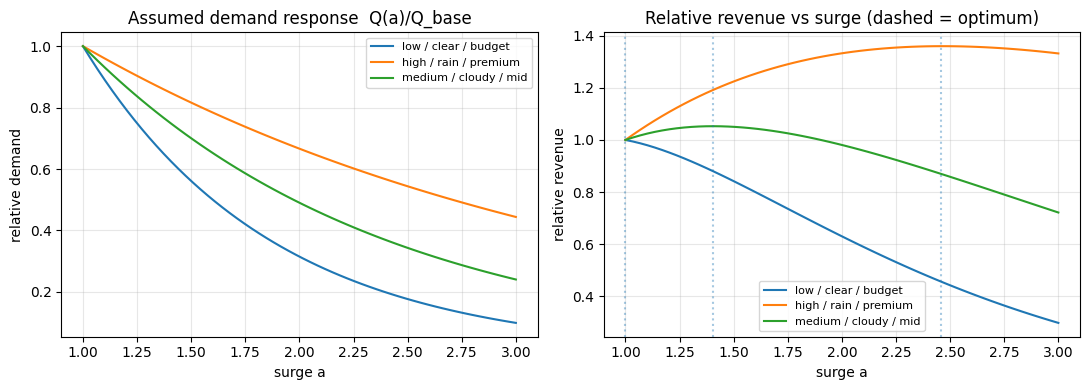

In [6]:
# build the environment + sanity-check baselines
env = DynamicPricingEnv(demand_table, EnvConfig())
print(f"[2] env: {env.n_states} states x {env.n_actions} actions | "
      f"{len(env.contexts):,} contexts | horizon {env.cfg.horizon}")

def pol_fixed(s): return SURGE_LEVELS.index(1.0)
def pol_max(s):   return len(SURGE_LEVELS) - 1
def pol_rule(s):
    dl, wx, prod, gb = s
    tgt = {"high": 1.5, "medium": 1.25, "low": 1.0}[dl]
    return int(np.argmin([abs(a - tgt) for a in SURGE_LEVELS]))

base = env.evaluate_policy(pol_fixed)
for name, pol in [("fixed 1.0 (baseline)", pol_fixed), ("always max 3.0", pol_max),
                  ("rule-based heuristic", pol_rule)]:
    v = env.evaluate_policy(pol)
    print(f"    {name:24s} {v:11.1f}  ({(v/base-1)*100:+.1f}% vs fixed)")
print(f"    {'oracle (best const)':24s} {best_constant_oracle(env):11.1f}  "
      f"({(best_constant_oracle(env)/base-1)*100:+.1f}% vs fixed)")

# demand-response figure (report figure)
a_grid = np.linspace(1.0, 3.0, 60)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for label, dl, wx, prod in [("low / clear / budget", "low", "clear", "Lyft"),
                            ("high / rain / premium", "high", "rain", "Lux Black"),
                            ("medium / cloudy / mid", "medium", "cloudy", "Lux")]:
    lam = compute_lambda(dl, wx, prod)
    dem = np.exp(-lam * (a_grid - 1.0)); rev = a_grid * dem
    ax[0].plot(a_grid, dem, label=label); ax[1].plot(a_grid, rev, label=label)
    ax[1].axvline(a_grid[int(np.argmax(rev))], ls=":", alpha=0.4)
ax[0].set_title("Assumed demand response  Q(a)/Q_base")
ax[0].set_xlabel("surge a"); ax[0].set_ylabel("relative demand")
ax[1].set_title("Relative revenue vs surge (dashed = optimum)")
ax[1].set_xlabel("surge a"); ax[1].set_ylabel("relative revenue")
for a in ax: a.legend(fontsize=8); a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/env_demand_response.png", dpi=120)
plt.show()

## 3 · Q-learning agent (reinforcement learning)

In [7]:
class QLearningAgent:
    def __init__(self, env, alpha_start=0.25, alpha_end=0.01, gamma=0.95,
                 eps_start=1.0, eps_end=0.02, seed=0):
        self.env = env
        self.alpha_start, self.alpha_end = alpha_start, alpha_end
        self.gamma = gamma
        self.eps_start, self.eps_end = eps_start, eps_end
        self.rng = np.random.default_rng(seed)
        self.Q = np.zeros((env.n_states, env.n_actions))
        self.hist_return, self.hist_td, self.hist_churn = [], [], []

    def act(self, s_idx, eps):
        if self.rng.random() < eps:
            return int(self.rng.integers(self.env.n_actions))
        return int(np.argmax(self.Q[s_idx]))

    def greedy_policy_fn(self):
        return lambda s: int(np.argmax(self.Q[self.env.state_index(s)]))

    def _reachable_greedy(self):
        return np.array([np.argmax(self.Q[i]) for i in self.env.reachable_state_indices()])

    def train(self, episodes=60000, decay_frac=0.7, churn_every=4000):
        n_ctx = len(self.env.contexts); decay = int(episodes * decay_frac)
        prev = None
        for ep in range(episodes):
            if ep < decay:
                f = ep / decay
                eps = self.eps_start * (self.eps_end / self.eps_start) ** f
                alpha = self.alpha_start * (self.alpha_end / self.alpha_start) ** f
            else:
                eps, alpha = self.eps_end, self.alpha_end
            s = self.env.reset(ep % n_ctx); s_idx = self.env.state_index(s)
            ep_ret, td_sum, td_n, done = 0.0, 0.0, 0, False
            while not done:
                a = self.act(s_idx, eps)
                s2, r, done, _ = self.env.step(a); ep_ret += r
                target = r if done else r + self.gamma * np.max(self.Q[self.env.state_index(s2)])
                td = target - self.Q[s_idx, a]
                self.Q[s_idx, a] += alpha * td
                td_sum += abs(td); td_n += 1
                if not done: s_idx = self.env.state_index(s2)
            self.hist_return.append(ep_ret); self.hist_td.append(td_sum / max(td_n, 1))
            if (ep + 1) % churn_every == 0:
                pol = self._reachable_greedy()
                if prev is not None:
                    self.hist_churn.append((ep + 1, int(np.sum(pol != prev))))
                prev = pol
        return self

In [8]:
# train the agent
agent = QLearningAgent(env, seed=0)
print("[3] training Q-learning (60k episodes) ...")
agent.train(episodes=60000)
q_policy_fn = agent.greedy_policy_fn()

rows = [("Fixed price (1.0x)", env.evaluate_policy(pol_fixed)),
        ("Always max (3.0x)", env.evaluate_policy(pol_max)),
        ("Rule-based heuristic", env.evaluate_policy(pol_rule)),
        ("Q-learning (learned)", env.evaluate_policy(q_policy_fn)),
        ("Oracle (best const)", best_constant_oracle(env))]
b = rows[0][1]
print("\n  policy                        exp.return    vs fixed")
for name, v in rows:
    print(f"  {name:28s} {v:11.1f}   {(v/b-1)*100:+6.1f}%")

np.save(f"{OUTPUT_DIR}/q_table.npy", agent.Q)
pd.DataFrame([{"demand_level": dl, "weather": wx, "product": prod,
               "goodwill_bucket": gb,
               "surge": env.actions[int(np.argmax(agent.Q[env.state_index((dl,wx,prod,gb))]))]}
    for dl in ["low","medium","high"] for wx in WEATHER_MULT
    for prod in PRODUCT_MULT for gb in range(N_GOODWILL_BUCKETS)]
    ).to_csv(f"{OUTPUT_DIR}/q_policy.csv", index=False)

[3] training Q-learning (60k episodes) ...

  policy                        exp.return    vs fixed
  Fixed price (1.0x)               28492.5     +0.0%
  Always max (3.0x)                25127.1    -11.8%
  Rule-based heuristic             31176.1     +9.4%
  Q-learning (learned)             31216.4     +9.6%
  Oracle (best const)              31351.6    +10.0%


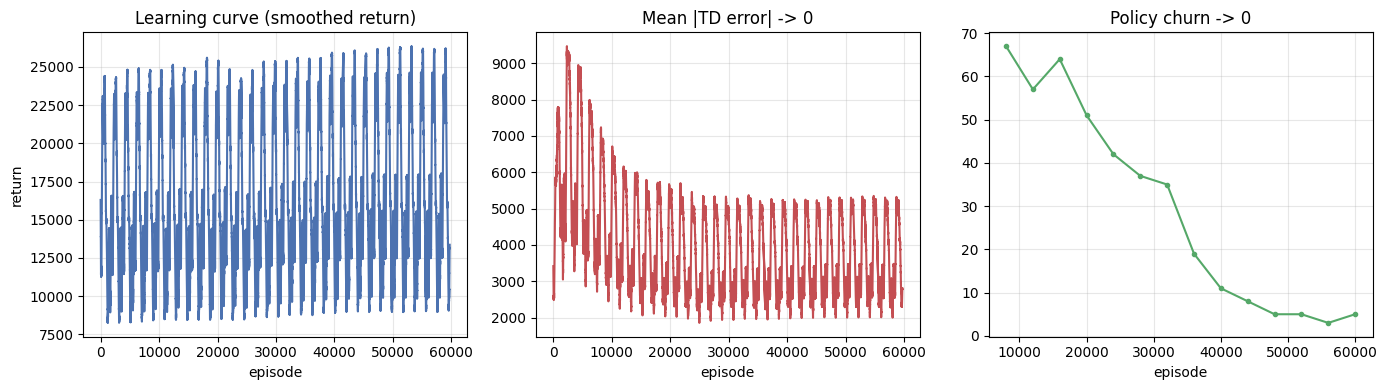

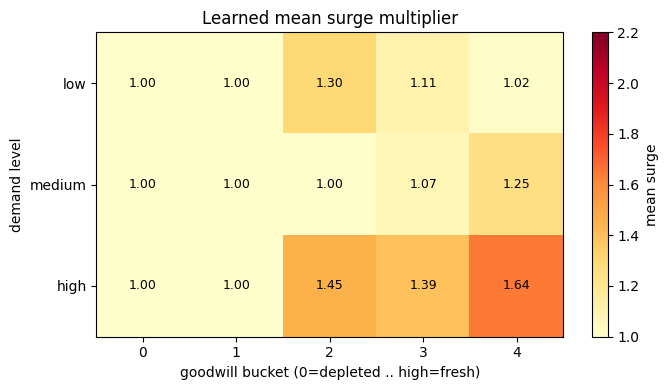

In [ ]:
# convergence diagnostics + learned-policy heatmap
ret = np.array(agent.hist_return); win = max(1, len(ret)//200)
sm = np.convolve(ret, np.ones(win)/win, mode="valid")
td = np.convolve(np.array(agent.hist_td), np.ones(win)/win, mode="valid")
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].plot(sm, color="#4C72B0"); ax[0].set_title("Learning curve (smoothed return)")
ax[0].set_xlabel("episode"); ax[0].set_ylabel("return"); ax[0].grid(alpha=0.3)
ax[1].plot(td, color="#C44E52"); ax[1].set_title("Mean |TD error| -> 0")
ax[1].set_xlabel("episode"); ax[1].grid(alpha=0.3)
if agent.hist_churn:
    ch = np.array(agent.hist_churn)
    ax[2].plot(ch[:,0], ch[:,1], marker="o", ms=3, color="#55A868")
ax[2].set_title("Policy churn -> 0"); ax[2].set_xlabel("episode"); ax[2].grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/q_learning_convergence.png", dpi=120); plt.show()

dls = ["low","medium","high"]; nb = N_GOODWILL_BUCKETS
grid = np.zeros((3, nb)); cnt = np.zeros((3, nb))
for c in env.contexts:
    di = dls.index(c["demand_level"])
    for gb in range(nb):
        a = env.actions[int(np.argmax(agent.Q[env.state_index(
            (c["demand_level"], c["weather"], c["product"], gb))]))]
        grid[di, gb] += a; cnt[di, gb] += 1
grid = np.where(cnt > 0, grid/np.maximum(cnt, 1), np.nan)
fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(grid, cmap="YlOrRd", aspect="auto", vmin=1.0, vmax=2.2)
ax.set_xticks(range(nb)); ax.set_yticks(range(3)); ax.set_yticklabels(dls)
ax.set_xlabel("goodwill bucket (0=depleted .. high=fresh)"); ax.set_ylabel("demand level")
ax.set_title("Learned mean surge multiplier")
for i in range(3):
    for j in range(nb):
        if not np.isnan(grid[i,j]):
            ax.text(j, i, f"{grid[i,j]:.2f}", ha="center", va="center", fontsize=9)
plt.colorbar(im, label="mean surge"); plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/q_policy_heatmap.png", dpi=120); plt.show()

## 4 · Genetic algorithm (evolutionary policy search)

In [9]:
class GeneticPolicySearch:
    def __init__(self, env, pop_size=120, tournament_k=3, p_crossover=0.9,
                 p_mutation=0.03, elitism=2, seed=0):
        self.env = env; self.pop_size = pop_size; self.k = tournament_k
        self.p_crossover = p_crossover; self.p_mutation = p_mutation
        self.elitism = elitism; self.rng = np.random.default_rng(seed)
        self.n_actions = env.n_actions
        self.state_ids = np.array(env.reachable_state_indices())
        self.genome_len = len(self.state_ids)
        self.pos_of_state = {sid: i for i, sid in enumerate(self.state_ids)}
        self._precompute_cells(); self.history = []

    def _precompute_cells(self):
        cells = {}
        for ci, c in enumerate(self.env.contexts):
            key = (c["demand_level"], c["weather"], c["product"])
            cells[key] = cells.get(key, 0.0) + \
                self.env.context_weights[ci] * c["base_price"] * c["q_base"]
        self.cell_keys = list(cells.keys())
        self.cell_coeff = np.array([cells[k] for k in self.cell_keys])
        self.cell_lambda = np.array([compute_lambda(*k) for k in self.cell_keys])
        nb = N_GOODWILL_BUCKETS
        self.cell_state_pos = np.zeros((len(self.cell_keys), nb), dtype=int)
        for j, (dl, wx, prod) in enumerate(self.cell_keys):
            for gb in range(nb):
                self.cell_state_pos[j, gb] = self.pos_of_state[
                    self.env.state_index((dl, wx, prod, gb))]

    def fitness(self, genome):
        cfg = self.env.cfg; surge = np.array(self.env.actions)
        gmin = cfg.goodwill_min; nb = N_GOODWILL_BUCKETS; total = 0.0
        for j in range(len(self.cell_keys)):
            lam = self.cell_lambda[j]; g, G = 1.0, 0.0
            for t in range(cfg.horizon):
                gb = int(min(nb-1, max(0, int((g-gmin)/(1.0-gmin+1e-9)*nb))))
                a = surge[genome[self.cell_state_pos[j, gb]]]
                decay = np.exp(-lam * (a - 1.0))
                G += (cfg.gamma ** t) * g * decay * (a - cfg.c_dissat * (a - 1.0))
                g = g - cfg.churn_rate*(a-1.0)*g + cfg.recovery_rate*(1.0-g)
                g = min(1.0, max(gmin, g))
            total += self.cell_coeff[j] * G
        return total

    def _random_genome(self): return self.rng.integers(0, self.n_actions, self.genome_len)
    def _tournament(self, pop, fits):
        idx = self.rng.integers(0, len(pop), self.k)
        return pop[idx[np.argmax(fits[idx])]].copy()
    def _crossover(self, p1, p2):
        if self.rng.random() > self.p_crossover: return p1.copy()
        return np.where(self.rng.random(self.genome_len) < 0.5, p1, p2)
    def _mutate(self, g):
        mask = self.rng.random(self.genome_len) < self.p_mutation
        n = int(mask.sum())
        if n: g[mask] = self.rng.integers(0, self.n_actions, n)
        return g

    def evolve(self, generations=150):
        pop = [self._random_genome() for _ in range(self.pop_size)]
        fits = np.array([self.fitness(g) for g in pop])
        for gen in range(generations):
            order = np.argsort(fits)[::-1]
            pop = [pop[i] for i in order]; fits = fits[order]
            self.history.append((gen, float(fits[0]), float(fits.mean())))
            new = [pop[i].copy() for i in range(self.elitism)]
            while len(new) < self.pop_size:
                new.append(self._mutate(self._crossover(
                    self._tournament(pop, fits), self._tournament(pop, fits))))
            pop = new; fits = np.array([self.fitness(g) for g in pop])
        self.best_genome = pop[int(np.argmax(fits))]
        self.best_fitness = float(np.max(fits))
        return self.best_genome

    def policy_fn(self, genome=None):
        g = self.best_genome if genome is None else genome
        return lambda s: int(g[self.pos_of_state[self.env.state_index(s)]])

[4] fitness factorisation verified exact. evolving (150 generations) ...
  Fixed price              28492.5     +0.0%
  Rule-based               31176.1     +9.4%
  Q-learning               31216.4     +9.6%
  Genetic algorithm        31351.8    +10.0%
  Oracle (ref)             31351.6    +10.0%


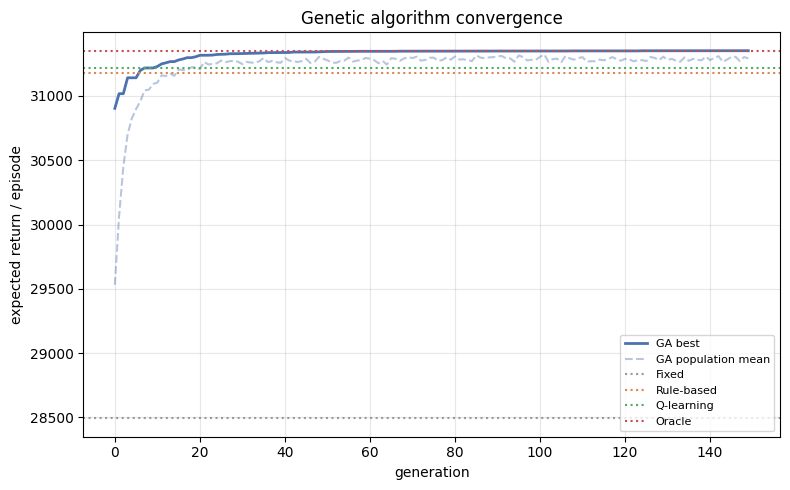

In [10]:
# evolve the policy
ga = GeneticPolicySearch(env, seed=0)
test = ga._random_genome()
assert abs(ga.fitness(test) - env.evaluate_policy(ga.policy_fn(test))) < 1e-6, \
    "fast fitness must equal env.evaluate_policy"
print("[4] fitness factorisation verified exact. evolving (150 generations) ...")
ga.evolve(generations=150)
ga_policy_fn = ga.policy_fn()

ql_val = env.evaluate_policy(q_policy_fn)
ga_val = env.evaluate_policy(ga_policy_fn)
oracle = best_constant_oracle(env); b = env.evaluate_policy(pol_fixed)
for name, v in [("Fixed price", b), ("Rule-based", env.evaluate_policy(pol_rule)),
                ("Q-learning", ql_val), ("Genetic algorithm", ga_val),
                ("Oracle (ref)", oracle)]:
    print(f"  {name:20s} {v:11.1f}   {(v/b-1)*100:+6.1f}%")

# GA convergence figure
h = np.array(ga.history)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(h[:,0], h[:,1], color="#4C72B0", lw=2, label="GA best")
ax.plot(h[:,0], h[:,2], color="#4C72B0", alpha=0.4, ls="--", label="GA population mean")
for nm, val, col in [("Fixed", b, "#999999"), ("Rule-based", env.evaluate_policy(pol_rule), "#DD8452"),
                     ("Q-learning", ql_val, "#55A868"), ("Oracle", oracle, "#C44E52")]:
    ax.axhline(val, ls=":", color=col, label=nm)
ax.set_xlabel("generation"); ax.set_ylabel("expected return / episode")
ax.set_title("Genetic algorithm convergence"); ax.legend(fontsize=8, loc="lower right")
ax.grid(alpha=0.3); plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/ga_convergence.png", dpi=120); plt.show()

pd.DataFrame([{"demand_level": dl, "weather": wx, "product": prod, "goodwill_bucket": gb,
               "surge": env.actions[ga_policy_fn((dl,wx,prod,gb))]}
    for dl in ["low","medium","high"] for wx in WEATHER_MULT for prod in PRODUCT_MULT
    for gb in range(N_GOODWILL_BUCKETS)
    if env.state_index((dl,wx,prod,gb)) in ga.pos_of_state]
    ).to_csv(f"{OUTPUT_DIR}/ga_policy.csv", index=False)

## 5 · Evaluation, baselines & robustness

A. comparison (noisy rollouts)
  Fixed price          exp=  28492.5  rollout=  29668.2 +/- 1082.4  ( +0.0%)
  Always max           exp=  25127.1  rollout=  25056.4 +/- 1009.0  (-11.8%)
  Rule-based           exp=  31176.1  rollout=  31148.6 +/- 1192.4  ( +9.4%)
  Q-learning           exp=  31216.4  rollout=  31404.1 +/- 1210.1  ( +9.6%)
  Genetic algorithm    exp=  31351.8  rollout=  32335.3 +/- 1226.0  (+10.0%)

  paired per-episode gain vs fixed (n=3000):
    Rule-based           + 1104.9 +/-  74.6  (60.8% of episodes)  [significant]
    Q-learning           + 1107.8 +/-  79.0  (52.5% of episodes)  [significant]
    Genetic algorithm    + 1190.6 +/-  82.0  (60.0% of episodes)  [significant]


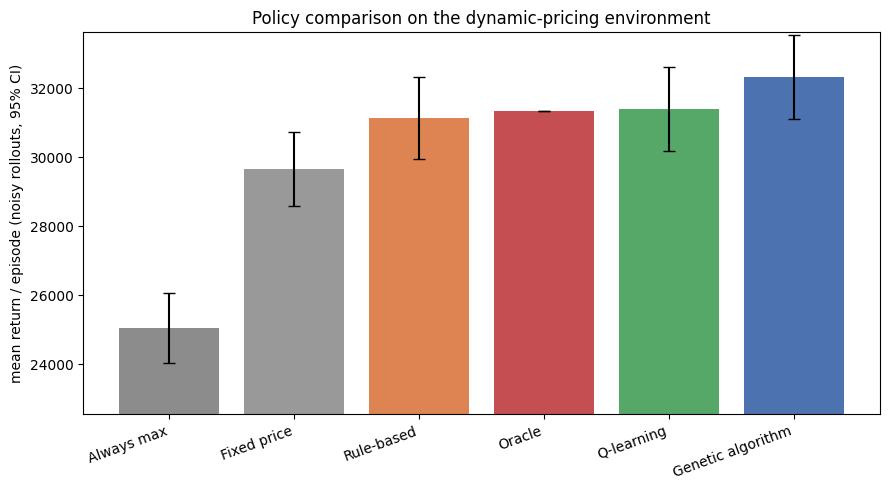

In [11]:
# A. noisy rollouts + paired significance
def rollout_returns(env, policy, n=2000, seed=1):
    env.rng = np.random.default_rng(seed); g = env.cfg.gamma; out = np.empty(n)
    for i in range(n):
        s = env.reset(); G, t, done = 0.0, 0, False
        while not done:
            s, r, done, _ = env.step(policy(s)); G += g**t * r; t += 1
        out[i] = G
    return out

def paired_diff(env, policy, base_policy, n=3000, seed=3):
    rng = np.random.default_rng(seed)
    ctx = rng.integers(0, len(env.contexts), n); seeds = rng.integers(0, 2**31-1, n)
    g = env.cfg.gamma; d = np.empty(n)
    for i in range(n):
        vals = []
        for pol in (policy, base_policy):
            env.rng = np.random.default_rng(seeds[i]); s = env.reset(int(ctx[i]))
            G, t, done = 0.0, 0, False
            while not done:
                s, r, done, _ = env.step(pol(s)); G += g**t * r; t += 1
            vals.append(G)
        d[i] = vals[0] - vals[1]
    return d.mean(), 1.96*d.std(ddof=1)/np.sqrt(n), float((d > 0).mean())*100

policies = {"Fixed price": pol_fixed, "Always max": pol_max, "Rule-based": pol_rule,
            "Q-learning": q_policy_fn, "Genetic algorithm": ga_policy_fn}
base_exp = env.evaluate_policy(pol_fixed); rowsA = []
print("A. comparison (noisy rollouts)")
for name, pol in policies.items():
    exp = env.evaluate_policy(pol); roll = rollout_returns(env, pol)
    ci = 1.96*roll.std(ddof=1)/np.sqrt(len(roll))
    rowsA.append({"method": name, "expected_return": exp, "rollout_mean": roll.mean(),
                  "ci95": ci, "pct_vs_fixed": (exp/base_exp-1)*100})
    print(f"  {name:20s} exp={exp:9.1f}  rollout={roll.mean():9.1f} +/- {ci:6.1f}  ({(exp/base_exp-1)*100:+5.1f}%)")
print("\n  paired per-episode gain vs fixed (n=3000):")
for name in ["Rule-based", "Q-learning", "Genetic algorithm"]:
    md_, ci, pct = paired_diff(env, policies[name], pol_fixed)
    print(f"    {name:20s} +{md_:7.1f} +/- {ci:5.1f}  ({pct:.1f}% of episodes)  "
          f"[{'significant' if md_-ci>0 else 'n.s.'}]")

df_a = pd.DataFrame(rowsA)
df_a = pd.concat([df_a, pd.DataFrame([{"method": "Oracle", "expected_return": oracle,
    "rollout_mean": oracle, "ci95": 0.0, "pct_vs_fixed": (oracle/base_exp-1)*100}])],
    ignore_index=True)

order = df_a.sort_values("rollout_mean").reset_index(drop=True)
colors = {"Fixed price": "#999999", "Always max": "#8C8C8C", "Rule-based": "#DD8452",
          "Q-learning": "#55A868", "Genetic algorithm": "#4C72B0", "Oracle": "#C44E52"}
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(order["method"], order["rollout_mean"], yerr=order["ci95"], capsize=4,
       color=[colors.get(n, "#4C72B0") for n in order["method"]])
ax.set_ylabel("mean return / episode (noisy rollouts, 95% CI)")
ax.set_title("Policy comparison on the dynamic-pricing environment")
ax.set_ylim(order["rollout_mean"].min()*0.9, order["rollout_mean"].max()*1.04)
plt.xticks(rotation=20, ha="right"); plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/comparison_bar.png", dpi=120); plt.show()

B. sensitivity to elasticity lambda (+/-20%)
  lambda x0.80:  RL=+16.5%  GA=+16.9%  rule=+14.8%  oracle=+19.1%
  lambda x0.90:  RL=+13.0%  GA=+13.4%  rule=+12.1%  oracle=+14.0%
  lambda x1.00:  RL= +9.6%  GA=+10.0%  rule= +9.4%  oracle=+10.0%
  lambda x1.10:  RL= +6.3%  GA= +6.7%  rule= +6.8%  oracle= +6.9%
  lambda x1.20:  RL= +3.1%  GA= +3.6%  rule= +4.3%  oracle= +4.6%


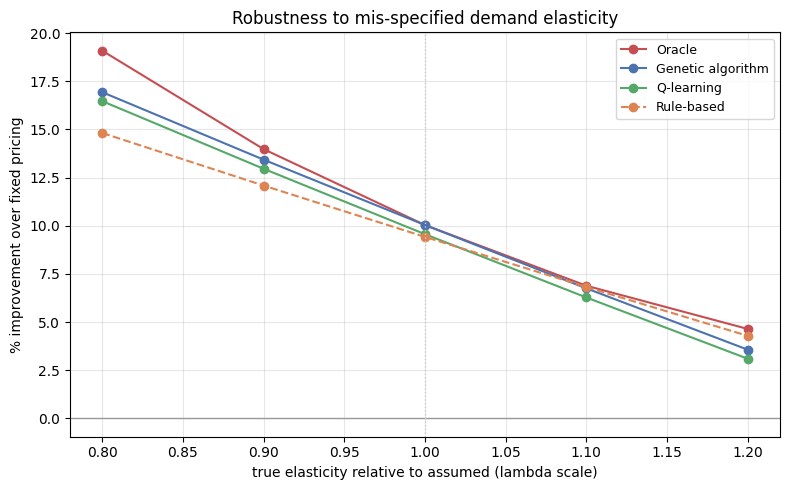

In [12]:
# B. sensitivity to the elasticity assumption
def part_b_sensitivity(dt, scales):
    global LAMBDA_SCALE
    recs = []
    try:
        for scale in scales:
            LAMBDA_SCALE = scale
            e = DynamicPricingEnv(dt, EnvConfig())
            bfix = e.evaluate_policy(pol_fixed)
            recs.append({"lambda_scale": scale,
                "Rule-based": (e.evaluate_policy(pol_rule)/bfix-1)*100,
                "Q-learning": (e.evaluate_policy(q_policy_fn)/bfix-1)*100,
                "Genetic algorithm": (e.evaluate_policy(ga_policy_fn)/bfix-1)*100,
                "Oracle": (best_constant_oracle(e)/bfix-1)*100})
            print(f"  lambda x{scale:.2f}:  RL={recs[-1]['Q-learning']:+5.1f}%  "
                  f"GA={recs[-1]['Genetic algorithm']:+5.1f}%  "
                  f"rule={recs[-1]['Rule-based']:+5.1f}%  oracle={recs[-1]['Oracle']:+5.1f}%")
    finally:
        LAMBDA_SCALE = 1.0   # always restore
    return pd.DataFrame(recs)

print("B. sensitivity to elasticity lambda (+/-20%)")
df_b = part_b_sensitivity(demand_table, [0.8, 0.9, 1.0, 1.1, 1.2])
fig, ax = plt.subplots(figsize=(8, 5))
for col, (c, ls) in {"Oracle": ("#C44E52","-"), "Genetic algorithm": ("#4C72B0","-"),
                     "Q-learning": ("#55A868","-"), "Rule-based": ("#DD8452","--")}.items():
    ax.plot(df_b["lambda_scale"], df_b[col], marker="o", color=c, ls=ls, label=col)
ax.axhline(0, color="#999999", lw=1); ax.axvline(1.0, color="#cccccc", ls=":", lw=1)
ax.set_xlabel("true elasticity relative to assumed (lambda scale)")
ax.set_ylabel("% improvement over fixed pricing")
ax.set_title("Robustness to mis-specified demand elasticity")
ax.legend(fontsize=9); ax.grid(alpha=0.3); plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/sensitivity_lambda.png", dpi=120); plt.show()

In [13]:
# C. held-out generalisation
print("C. held-out generalisation (70/30 context split)")
rng = np.random.default_rng(7)
mask = rng.random(len(demand_table)) < 0.7
dt_tr = demand_table[mask].reset_index(drop=True)
dt_te = demand_table[~mask].reset_index(drop=True)
env_tr, env_te = DynamicPricingEnv(dt_tr, EnvConfig()), DynamicPricingEnv(dt_te, EnvConfig())

ga_ho = GeneticPolicySearch(env_tr, seed=0); ga_ho.evolve(generations=120)
train_lut = {}
for dl in ["low","medium","high"]:
    for wx in WEATHER_MULT:
        for prod in PRODUCT_MULT:
            for gb in range(N_GOODWILL_BUCKETS):
                s = (dl, wx, prod, gb)
                if env_tr.state_index(s) in ga_ho.pos_of_state:
                    train_lut[s] = ga_ho.policy_fn()(s)
ho_pol = lambda s: train_lut.get(s, SURGE_LEVELS.index(1.0))
tr = (env_tr.evaluate_policy(ho_pol)/env_tr.evaluate_policy(pol_fixed)-1)*100
te = (env_te.evaluate_policy(ho_pol)/env_te.evaluate_policy(pol_fixed)-1)*100
print(f"  trained on {len(dt_tr)} contexts, tested on {len(dt_te)} unseen")
print(f"  improvement over fixed:  train={tr:+.1f}%   held-out test={te:+.1f}%   gap={tr-te:+.1f} pts")
df_a.to_csv(f"{OUTPUT_DIR}/results_summary.csv", index=False)
df_b.to_csv(f"{OUTPUT_DIR}/sensitivity_summary.csv", index=False)
print("\n[5] wrote results_summary.csv and sensitivity_summary.csv")

C. held-out generalisation (70/30 context split)
  trained on 1356 contexts, tested on 588 unseen
  improvement over fixed:  train=+10.1%   held-out test=+10.0%   gap=+0.1 pts

[5] wrote results_summary.csv and sensitivity_summary.csv


## 6 · Summary of results

In [14]:
print(" RESULTS SUMMARY".center(58))
print(df_a[["method","expected_return","pct_vs_fixed"]].round(1).to_string(index=False))
print("\nAll outputs in ./%s/:" % OUTPUT_DIR)
for f in sorted(os.listdir(OUTPUT_DIR)):
    print("   ", f)

                      RESULTS SUMMARY                     
           method  expected_return  pct_vs_fixed
      Fixed price          28492.5           0.0
       Always max          25127.1         -11.8
       Rule-based          31176.1           9.4
       Q-learning          31216.4           9.6
Genetic algorithm          31351.8          10.0
           Oracle          31351.6          10.0

All outputs in ./outputs/:
    base_price_model.csv
    comparison_bar.png
    demand_table.csv
    eda_demand_by_tod.png
    eda_price_vs_distance.png
    eda_surge_dist.png
    env_demand_response.png
    ga_convergence.png
    ga_policy.csv
    q_learning_convergence.png
    q_policy.csv
    q_policy_heatmap.png
    q_table.npy
    results_summary.csv
    sensitivity_lambda.png
    sensitivity_summary.csv
